# Models Evaluation

In [1]:
from pathlib import Path
import sys

project_root = Path.cwd()
if not (project_root / 'main.py').exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from config import config
from evaluation import compare_models

## Данные и разбиение

In [2]:
data = pd.read_csv(config.paths.train_data)

X = data.drop(columns=[config.general.target])
y = data[config.general.target]

X.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

## Сравнение моделей

In [4]:
results = compare_models(X_train, y_train, config)
results

,Model,CV Mean,CV Std
0,catboost,0.839606,0.044812
1,random_forest,0.833154,0.045630
2,xgboost,0.826754,0.037926
3,knn,0.825064,0.038203
4,decision_tree,0.810727,0.034848
5,logistic_regression,0.802791,0.045519


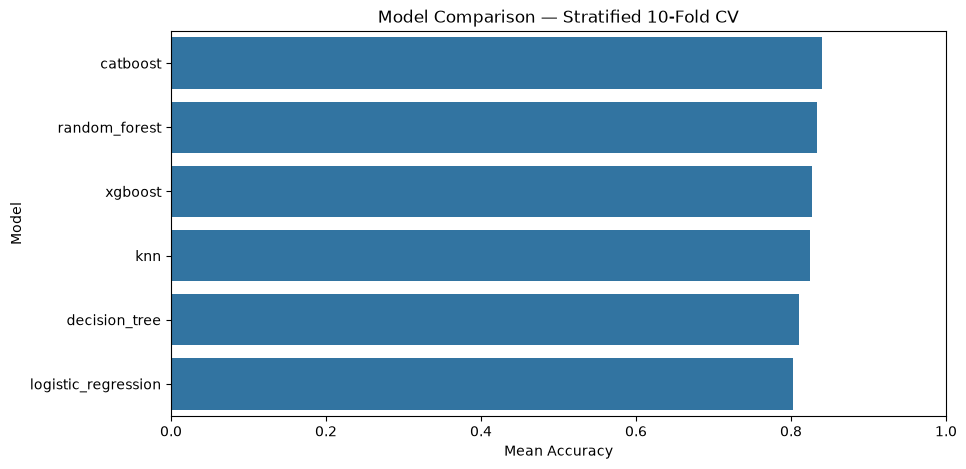

In [5]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='CV Mean',
    y='Model',
)

plt.title('Model Comparison — Stratified 10-Fold CV')
plt.xlabel('Mean Accuracy')
plt.ylabel('Model')
plt.xlim(0, 1)
plt.show()

Базово catboost показывает наивысшую точность

## Deep Learning

In [6]:
import torch
from dl import prepare_data, MLP, train_model

In [7]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=config.split.test_size,
    random_state=config.general.seed,
    stratify=y
)

train_dataset, val_dataset, _, _ = prepare_data(X_train, X_val, y_train, y_val)

In [8]:
model = MLP(
    input_dim=train_dataset.tensors[0].shape[1]
).to(device)

best_model_state = train_model(model, train_dataset, val_dataset, device)

model.load_state_dict(best_model_state)

Epoch 1/100 | Train Loss: 0.6924 | Val Loss: 0.6760 | Val Accuracy: 0.5784
Epoch 2/100 | Train Loss: 0.6580 | Val Loss: 0.6448 | Val Accuracy: 0.6082
Epoch 3/100 | Train Loss: 0.6273 | Val Loss: 0.6176 | Val Accuracy: 0.7052
Epoch 4/100 | Train Loss: 0.6003 | Val Loss: 0.5923 | Val Accuracy: 0.7500
Epoch 5/100 | Train Loss: 0.5761 | Val Loss: 0.5694 | Val Accuracy: 0.7687
Epoch 6/100 | Train Loss: 0.5532 | Val Loss: 0.5478 | Val Accuracy: 0.7948
Epoch 7/100 | Train Loss: 0.5331 | Val Loss: 0.5275 | Val Accuracy: 0.8022
Epoch 8/100 | Train Loss: 0.5143 | Val Loss: 0.5097 | Val Accuracy: 0.8060
Epoch 9/100 | Train Loss: 0.4985 | Val Loss: 0.4938 | Val Accuracy: 0.8134
Epoch 10/100 | Train Loss: 0.4845 | Val Loss: 0.4789 | Val Accuracy: 0.8246
Epoch 11/100 | Train Loss: 0.4720 | Val Loss: 0.4667 | Val Accuracy: 0.8209
Epoch 12/100 | Train Loss: 0.4615 | Val Loss: 0.4569 | Val Accuracy: 0.8172
Epoch 13/100 | Train Loss: 0.4535 | Val Loss: 0.4483 | Val Accuracy: 0.8134
Epoch 14/100 | Train 

<All keys matched successfully>

## Подбор гиперпараметров

In [9]:
from tuning import tune_all_models

In [10]:
results, best_models = tune_all_models(
    X_train,
    y_train,
    config
)

results


Tuning logistic_regression...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Tuning knn...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Tuning decision_tree...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Tuning random_forest...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Tuning xgboost...
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Tuning catboost...
Fitting 5 folds for each of 72 candidates, totalling 360 fits


,Model,CV Mean,CV Std,Best Params
0,catboost,0.839548,0.031396,"{'model__depth': 4, 'model__iterations': 500, ..."
1,xgboost,0.837935,0.022536,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,random_forest,0.833135,0.027595,"{'model__max_depth': 5, 'model__min_samples_le..."
3,knn,0.817110,0.028798,"{'model__n_neighbors': 15, 'model__p': 2, 'mod..."
4,decision_tree,0.815497,0.036491,"{'model__max_depth': 3, 'model__min_samples_le..."
5,logistic_regression,0.804271,0.028365,{'model__C': 0.01}


In [11]:
results.loc[
    results['Model'] == 'catboost',
    'Best Params'
].iloc[0]

{'model__depth': 4,
 'model__iterations': 500,
 'model__l2_leaf_reg': 3,
 'model__learning_rate': 0.01}

После настройки гиперпараметров catboost продолжает показывать наивысшую точность, можем использовать его лучшую конфигурацию параметров для построения решения